this is reading data ,

In [21]:
import pandas as pd 
data = pd.read_csv('./reviews.csv',encoding='utf-8')
print(data)
print(data.describe(),data.info())
data = data[data['Rating'] != 'Rating']

     Rating                                        Review Text
0         5  هواکش ساختمان بغلی خیلی مزاحم بود قیمت اتاق ها...
1         3  هتل عالی نبود ولی بد هم نبود سیستم گرمایشی خوب...
2         5  همه چیز خوب بود فقط نانی که در رستوران پخت میش...
3         4  سلام همه چیز عالی بود.(فقط یک نکته کوچک در مور...
4         5  در کل هتل مرتب و خوبی بود، در مقایسه اتاق هایش...
...     ...                                                ...
3414      4  سلام به نظرم یک وعده بصورت رزور پیشنهادی بود ب...
3415      4               در حد چهار ستاره نیست ولی قابل قبوله
3416      4  به نظر بنده با توجه به اینکه ساعات ورود قطار م...
3417      4                                          بسیار خوب
3418      4  باسلام باتشکرازهمه اقای حیدرزاده پرسنل رستوران...

[3419 rows x 2 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3419 entries, 0 to 3418
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Rating       3419 non-null

In [22]:
# data = data.drop_duplicates(inplace=True)
# print(data)

text = data['Review Text']
text_raw_copy = text.copy(deep=True)
target = data['Rating']
# print(text , target)
print(target.unique())
print(target , text)



['5' '3' '4' '2' '1']
0       5
1       3
2       5
3       4
4       5
       ..
3414    4
3415    4
3416    4
3417    4
3418    4
Name: Rating, Length: 3398, dtype: object 0       هواکش ساختمان بغلی خیلی مزاحم بود قیمت اتاق ها...
1       هتل عالی نبود ولی بد هم نبود سیستم گرمایشی خوب...
2       همه چیز خوب بود فقط نانی که در رستوران پخت میش...
3       سلام همه چیز عالی بود.(فقط یک نکته کوچک در مور...
4       در کل هتل مرتب و خوبی بود، در مقایسه اتاق هایش...
                              ...                        
3414    سلام به نظرم یک وعده بصورت رزور پیشنهادی بود ب...
3415                 در حد چهار ستاره نیست ولی قابل قبوله
3416    به نظر بنده با توجه به اینکه ساعات ورود قطار م...
3417                                            بسیار خوب
3418    باسلام باتشکرازهمه اقای حیدرزاده پرسنل رستوران...
Name: Review Text, Length: 3398, dtype: object


proccessing and saving 

## Text Preprocessing:

* Normalization: Standardize characters and fix spacing issues.
* Tokenization: Split text into individual tokens (words, punctuation, etc.).
* Stemming: Reduce words to their root forms.
* Lemmatization: Convert words to their lemma forms.
* Part-of-Speech Tagging: Tag tokens with their parts of speech (if necessary for your application).

In [23]:
from hazm import Normalizer
normalizer = Normalizer()
text = text.apply(lambda x: normalizer.normalize(x))
print(text)



0       هواکش ساختمان بغلی خیلی مزاحم بود قیمت اتاق‌ها...
1       هتل عالی نبود ولی بد هم نبود سیستم گرمایشی خوب...
2       همه چیز خوب بود فقط نانی که در رستوران پخت می‌...
3       سلام همه چیز عالی بود. (فقط یک نکته کوچک در مو...
4       در کل هتل مرتب و خوبی بود، در مقایسه اتاق هایش...
                              ...                        
3414    سلام به نظرم یک وعده بصورت رزور پیشنهادی بود ب...
3415                 در حد چهار ستاره نیست ولی قابل قبوله
3416    به نظر بنده با توجه به اینکه ساعات ورود قطار م...
3417                                            بسیار خوب
3418    باسلام باتشکرازهمه اقای حیدرزاده پرسنل رستوران...
Name: Review Text, Length: 3398, dtype: object


In [24]:
from hazm import word_tokenize

text = text.apply(lambda x : word_tokenize(x))
print(text)

0       [هواکش, ساختمان, بغلی, خیلی, مزاحم, بود, قیمت,...
1       [هتل, عالی, نبود, ولی, بد, هم, نبود, سیستم, گر...
2       [همه, چیز, خوب, بود, فقط, نانی, که, در, رستورا...
3       [سلام, همه, چیز, عالی, بود, ., (, فقط, یک, نکت...
4       [در, کل, هتل, مرتب, و, خوبی, بود, ،, در, مقایس...
                              ...                        
3414    [سلام, به, نظرم, یک, وعده, بصورت, رزور, پیشنها...
3415        [در, حد, چهار, ستاره, نیست, ولی, قابل, قبوله]
3416    [به, نظر, بنده, با, توجه, به, اینکه, ساعات, ور...
3417                                         [بسیار, خوب]
3418    [باسلام, باتشکرازهمه, اقای, حیدرزاده, پرسنل, ر...
Name: Review Text, Length: 3398, dtype: object


In [25]:
from hazm import Stemmer

stemmer = Stemmer()

text = text.apply(lambda x: [stemmer.stem(token) for token in x])
print(text)

0       [هواک, ساخ, بغل, خیل, مزاح, بود, قیم, اتاق, زی...
1       [هتل, عال, نبود, ول, بد, ه, نبود, سیس, گرمایش,...
2       [همه, چیز, خوب, بود, فقط, نان, که, در, رستور, ...
3       [سلا, همه, چیز, عال, بود, ., (, فقط, یک, نکته,...
4       [در, کل, هتل, مرتب, و, خوب, بود, ،, در, مقایسه...
                              ...                        
3414    [سلا, به, نظر, یک, وعده, بصور, رزور, پیشنهاد, ...
3415          [در, حد, چهار, ستاره, نیس, ول, قابل, قبوله]
3416    [به, نظر, بنده, با, توجه, به, اینکه, ساع, ورود...
3417                                         [بسیار, خوب]
3418    [باسلا, باتشکرازهمه, اقا, حیدرزاده, پرسنل, رست...
Name: Review Text, Length: 3398, dtype: object


In [26]:
from hazm import Lemmatizer
lemmatizer = Lemmatizer()

text =text.apply(lambda x : [lemmatizer.lemmatize(token) for token in x])
print(text)

0       [هواک, ساخ, بغل, خیل, مزاح, بود#است, قیم, اتاق...
1       [هتل, عال, بود#است, ول, بد, #هست, بود#است, سیس...
2       [همه, چیز, خوب, بود#است, فقط, نان, که, در, رست...
3       [سلا, همه, چیز, عال, بود#است, ., (, فقط, یک, ن...
4       [در, کل, هتل, مرتب, و, خوب, بود#است, ،, در, مق...
                              ...                        
3414    [سلا, به, نظر, یک, وعده, بصور, رزور, پیشنهاد, ...
3415          [در, حد, چهار, ستاره, نیس, ول, قابل, قبوله]
3416    [به, نظر, بنده, با, توجه, به, اینکه, ساع, ورود...
3417                                         [بسیار, خوب]
3418    [باسلا, باتشکرازهمه, اقا, حیدرزاده, پرسنل, رست...
Name: Review Text, Length: 3398, dtype: object


In [27]:
merged_Data = pd.concat([text, target], axis=1)

print(merged_Data)

merged_Data.to_csv('processed.csv',index=False)

                                            Review Text Rating
0     [هواک, ساخ, بغل, خیل, مزاح, بود#است, قیم, اتاق...      5
1     [هتل, عال, بود#است, ول, بد, #هست, بود#است, سیس...      3
2     [همه, چیز, خوب, بود#است, فقط, نان, که, در, رست...      5
3     [سلا, همه, چیز, عال, بود#است, ., (, فقط, یک, ن...      4
4     [در, کل, هتل, مرتب, و, خوب, بود#است, ،, در, مق...      5
...                                                 ...    ...
3414  [سلا, به, نظر, یک, وعده, بصور, رزور, پیشنهاد, ...      4
3415        [در, حد, چهار, ستاره, نیس, ول, قابل, قبوله]      4
3416  [به, نظر, بنده, با, توجه, به, اینکه, ساع, ورود...      4
3417                                       [بسیار, خوب]      4
3418  [باسلا, باتشکرازهمه, اقا, حیدرزاده, پرسنل, رست...      4

[3398 rows x 2 columns]


## Vectorizing

Bag-of-Words (BoW):

BoW representation represents text as a collection of words, disregarding grammar and word order.
Each document is represented by a vector where each element corresponds to the count (or frequency) of a particular word in the vocabulary.
BoW can be created using the CountVectorizer from scikit-learn.
Term Frequency-Inverse Document Frequency (TF-IDF):

TF-IDF represents the importance of a word in a document relative to a collection of documents (corpus).
It combines term frequency (TF), which measures the frequency of a word in a document, with inverse document frequency (IDF), which penalizes words that are common across the corpus.
TF-IDF can be created using the TfidfVectorizer from scikit-learn.
Word Embeddings:

Word embeddings represent words as dense vectors in a continuous vector space.
They capture semantic relationships between words and are learned based on the distributional properties of words in a large corpus.
Popular word embedding algorithms include Word2Vec, GloVe, and FastText.
Pre-trained word embeddings can be used directly or fine-tuned on specific datasets.
Character-level Embeddings:

Character-level embeddings represent words as sequences of characters rather than individual words.
They capture morphological and orthographic information and are useful for handling out-of-vocabulary words.
Character-level embeddings can be combined with word embeddings or used independently.
N-grams:

N-grams represent contiguous sequences of n words in a document.
They capture local syntactic and semantic information and are useful for capturing context.
N-grams can be combined with BoW or TF-IDF representations to include sequential information.
Hashing Vectorization:

Hashing vectorization represents text using a fixed-size vector where each feature is hashed to a particular index in the vector space.
It is memory-efficient and suitable for large text datasets but does not provide feature interpretability.

In [28]:
from sklearn.feature_extraction.text import CountVectorizer


string = [' '.join(tokens) for tokens in text]

vectorizer = CountVectorizer()
bow_matrix = vectorizer.fit_transform(string)

bow_df = pd.DataFrame(bow_matrix.toarray(), columns=vectorizer.get_feature_names_out())
print(bow_df)


      _اتاق  _خد  _خراب  _رفتار  _صبحانه  _قیم  _موقع  _نظار  _هر  _پاک  ...  \
0         0    0      0       0        0     0      0      0    0     0  ...   
1         0    0      0       0        0     0      0      0    0     0  ...   
2         0    0      0       0        0     0      0      0    0     0  ...   
3         0    0      0       0        0     0      0      0    0     0  ...   
4         0    0      0       0        0     0      0      0    0     0  ...   
...     ...  ...    ...     ...      ...   ...    ...    ...  ...   ...  ...   
3393      0    0      0       0        0     0      0      0    0     0  ...   
3394      0    0      0       0        0     0      0      0    0     0  ...   
3395      0    0      0       0        0     0      0      0    0     0  ...   
3396      0    0      0       0        0     0      0      0    0     0  ...   
3397      0    0      0       0        0     0      0      0    0     0  ...   

      ۷۵  ۸۰  ۸۵  ۸۵۰۰۰  ۹۰  ۹۴  ۹۵  ۹۶

In [29]:
from sklearn.feature_extraction.text import TfidfVectorizer


text_strings = [' '.join(tokens) for tokens in text]

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(text_strings)

vocabulary = tfidf_vectorizer.get_feature_names_out()
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=vocabulary)
print(tfidf_df)


      _اتاق  _خد  _خراب  _رفتار  _صبحانه  _قیم  _موقع  _نظار  _هر  _پاک  ...  \
0       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
1       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
2       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
4       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
...     ...  ...    ...     ...      ...   ...    ...    ...  ...   ...  ...   
3393    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3394    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3395    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3396    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3397    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   

       ۷۵   ۸۰   ۸۵  ۸۵۰۰۰   ۹۰   ۹۴   

In [30]:
from sklearn.feature_extraction.text import TfidfVectorizer

text_strings = [' '.join(tokens) for tokens in text]

tfidf_vectorizer = TfidfVectorizer(ngram_range=(1, 1))  # Includes unigrams and bigrams
tfidf_vectors = tfidf_vectorizer.fit_transform(text_strings)

print("TF-IDF Vectors with unigrams and bigrams:")
vocabulary = tfidf_vectorizer.get_feature_names_out()
tfidfNgram_df = pd.DataFrame(tfidf_vectors.toarray(), columns=vocabulary)
print(tfidfNgram_df)

# not helping

TF-IDF Vectors with unigrams and bigrams:
      _اتاق  _خد  _خراب  _رفتار  _صبحانه  _قیم  _موقع  _نظار  _هر  _پاک  ...  \
0       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
1       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
2       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
4       0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
...     ...  ...    ...     ...      ...   ...    ...    ...  ...   ...  ...   
3393    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3394    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3395    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3396    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...   
3397    0.0  0.0    0.0     0.0      0.0   0.0    0.0    0.0  0.0   0.0  ...  

In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

text_strings = [' '.join(tokens) for tokens in text]

tfidf_vectorizer = TfidfVectorizer(ngram_range=(1,2))  # Includes unigrams and bigrams
tfidf_vectors = tfidf_vectorizer.fit_transform(text_strings)

print("TF-IDF Vectors with unigrams and bigrams:")
vocabulary = tfidf_vectorizer.get_feature_names_out()
tfidfNgram1to2_df = pd.DataFrame(tfidf_vectors.toarray(), columns=vocabulary)
print(tfidfNgram1to2_df)

TF-IDF Vectors with unigrams and bigrams:
      _اتاق  _اتاق تمیز  _خد  _خد درجه  _خراب  _خراب تلوزیون  _رفتار  \
0       0.0         0.0  0.0       0.0    0.0            0.0     0.0   
1       0.0         0.0  0.0       0.0    0.0            0.0     0.0   
2       0.0         0.0  0.0       0.0    0.0            0.0     0.0   
3       0.0         0.0  0.0       0.0    0.0            0.0     0.0   
4       0.0         0.0  0.0       0.0    0.0            0.0     0.0   
...     ...         ...  ...       ...    ...            ...     ...   
3393    0.0         0.0  0.0       0.0    0.0            0.0     0.0   
3394    0.0         0.0  0.0       0.0    0.0            0.0     0.0   
3395    0.0         0.0  0.0       0.0    0.0            0.0     0.0   
3396    0.0         0.0  0.0       0.0    0.0            0.0     0.0   
3397    0.0         0.0  0.0       0.0    0.0            0.0     0.0   

      _رفتار مناسب  _صبحانه  _صبحانه عال  ...  ۹۷ بود  ۹۷ تو  ۹۷ دو  ۹۷ سفر  \
0             

In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer

text_strings = [' '.join(tokens) for tokens in text]

tfidf_vectorizer = TfidfVectorizer(ngram_range=(2,2))  # Includes unigrams and bigrams
tfidf_vectors = tfidf_vectorizer.fit_transform(text_strings)

print("TF-IDF Vectors with unigrams and bigrams:")
vocabulary = tfidf_vectorizer.get_feature_names_out()
tfidfNgram3_df = pd.DataFrame(tfidf_vectors.toarray(), columns=vocabulary)
print(tfidfNgram3_df)

TF-IDF Vectors with unigrams and bigrams:
      _اتاق تمیز  _خد درجه  _خراب تلوزیون  _رفتار مناسب  _صبحانه عال  \
0            0.0       0.0            0.0           0.0          0.0   
1            0.0       0.0            0.0           0.0          0.0   
2            0.0       0.0            0.0           0.0          0.0   
3            0.0       0.0            0.0           0.0          0.0   
4            0.0       0.0            0.0           0.0          0.0   
...          ...       ...            ...           ...          ...   
3393         0.0       0.0            0.0           0.0          0.0   
3394         0.0       0.0            0.0           0.0          0.0   
3395         0.0       0.0            0.0           0.0          0.0   
3396         0.0       0.0            0.0           0.0          0.0   
3397         0.0       0.0            0.0           0.0          0.0   

      _قیم بالا  _موقع ورود  _نظار عال  _هر کار  _پاک تمیز  ...  ۹۷ برا  \
0           0.0   

Count Vectorization (Bag of Words): This method represents text data as a matrix where rows correspond to documents and columns correspond to terms in the vocabulary. Each cell in the matrix represents the frequency of a term in a document. It's often used with algorithms like Naive Bayes and Logistic Regression.

TF-IDF Vectorization: Term Frequency-Inverse Document Frequency (TF-IDF) measures the importance of a term in a document relative to a corpus. It downweights terms that appear frequently across documents and upweights terms that are unique to a document. It's useful for tasks like text classification and information retrieval.

Word Embeddings (e.g., Word2Vec, GloVe): Word embeddings represent words as dense vectors in a continuous vector space. They capture semantic relationships between words and can be trained on large text corpora. Word embeddings are commonly used in tasks like semantic similarity, sentiment analysis, and named entity recognition.


Character N-grams: Instead of tokenizing text into words, character n-grams represent sequences of characters. This approach captures morphological and syntactical information and is useful for languages with complex morphology.

## Machine Learning : 
Split your data: Divide your dataset into training and testing sets to evaluate the performance of your models. You can use techniques like train-test split or cross-validation.

Model Training: Train each of your chosen machine learning algorithms using the training data. Make sure to import the necessary modules from scikit-learn (sklearn) to create and train these models.

Model Evaluation: Evaluate the performance of each model using the testing set. For classification tasks, you can consider metrics like accuracy, precision, recall, F1-score, and ROC-AUC. For regression tasks, metrics like mean squared error (MSE), mean absolute error (MAE), and R-squared can be used.

Hyperparameter Tuning (Optional): Depending on the algorithm, you might want to tune its hyperparameters to improve performance. Techniques like grid search or randomized search can be used for hyperparameter optimization.

Comparison: Compare the performance of different models based on the evaluation metrics. Choose the model that performs best on your task and dataset.

In [33]:
import warnings

# Ignore all warnings
warnings.filterwarnings("ignore")

# Ignore specific category of warnings
# Example: ignoring all DeprecationWarnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Ignore specific warning messages by message
# Example: ignoring specific FutureWarning message
warnings.filterwarnings("ignore", message="specific warning message")

# Restore default behavior (show all warnings)
# warnings.resetwarnings()


In [34]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import classification_report

# Step 1: Split the data
X_train, X_test, y_train, y_test = train_test_split(bow_df, target, test_size=0.2, random_state=42)

# Step 2: Model Training
nb_classifier = MultinomialNB()
nb_classifier.fit(X_train, y_train)

svc_classifier = SVC()
svc_classifier.fit(X_train, y_train)

cart_classifier = DecisionTreeClassifier()
cart_classifier.fit(X_train, y_train)

logistic_classifier = LogisticRegression()
logistic_classifier.fit(X_train, y_train)

mlp_classifier = MLPClassifier()
mlp_classifier.fit(X_train, y_train)

xgb_classifier = GradientBoostingClassifier()
xgb_classifier.fit(X_train, y_train)

# Step 3: Model Evaluation
nb_pred = nb_classifier.predict(X_test)
print("Naïve Bayes:")
print(classification_report(y_test, nb_pred))

svc_pred = svc_classifier.predict(X_test)
print("SVC:")
print(classification_report(y_test, svc_pred))

cart_pred = cart_classifier.predict(X_test)
print("CART:")
print(classification_report(y_test, cart_pred))

logistic_pred = logistic_classifier.predict(X_test)
print("Logistic Regression:")
print(classification_report(y_test, logistic_pred))

mlp_pred = mlp_classifier.predict(X_test)
print("MLP:")
print(classification_report(y_test, mlp_pred))

xgb_pred = xgb_classifier.predict(X_test)
print("XGBoost:")
print(classification_report(y_test, xgb_pred))


Naïve Bayes:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       1.00      0.17      0.29         6
           3       0.68      0.26      0.38        57
           4       0.69      0.77      0.73       281
           5       0.79      0.82      0.81       328

    accuracy                           0.74       680
   macro avg       0.63      0.40      0.44       680
weighted avg       0.73      0.74      0.72       680

SVC:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       1.00      0.17      0.29         6
           3       1.00      0.26      0.42        57
           4       0.66      0.86      0.75       281
           5       0.84      0.76      0.79       328

    accuracy                           0.75       680
   macro avg       0.70      0.41      0.45       680
weighted avg       0.77      0.75      0.73       680

CART

In [37]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt 
import seaborn as sns
print("Naïve Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print("SVC Accuracy:", accuracy_score(y_test, svc_pred))
print("CART Accuracy:", accuracy_score(y_test, cart_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_pred))
print("MLP Accuracy:", accuracy_score(y_test, mlp_pred))
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))


Naïve Bayes Accuracy: 0.7382352941176471
SVC Accuracy: 0.7455882352941177
CART Accuracy: 0.8147058823529412
Logistic Regression Accuracy: 0.8235294117647058
MLP Accuracy: 0.836764705882353
XGBoost Accuracy: 0.7088235294117647


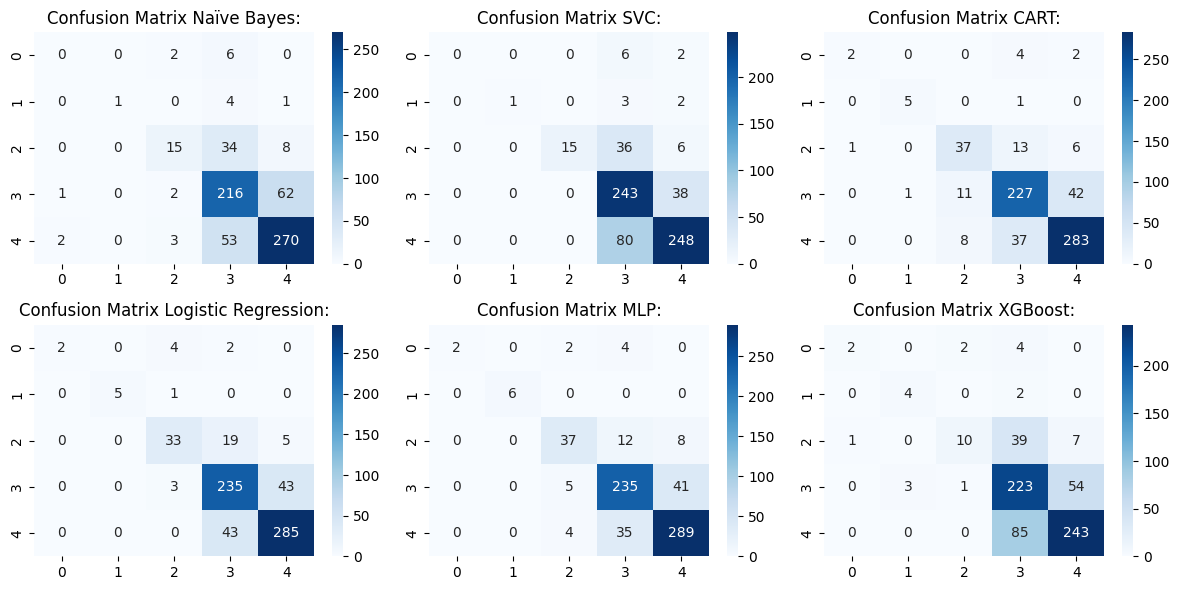

In [38]:
list = [nb_pred, svc_pred,cart_pred,logistic_pred,mlp_pred,xgb_pred]
list_name =["Confusion Matrix Naïve Bayes:" ,"Confusion Matrix SVC:" ,"Confusion Matrix CART:",
             "Confusion Matrix Logistic Regression:","Confusion Matrix MLP:","Confusion Matrix XGBoost:"]
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 6))
j = 0
for i, name in zip(list, list_name):
    subplot = ax[j // 3, j % 3]
    subplot.set_title(name)
    cm = confusion_matrix(y_test, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=subplot)
    j += 1

plt.tight_layout()
plt.show()

Result for tfidf method 

In [39]:
X_train, X_test, y_train, y_test = train_test_split(tfidf_df, target, test_size=0.2, random_state=42)

tf_nb_classifier = MultinomialNB()
tf_nb_classifier.fit(X_train, y_train)

tf_svc_classifier = SVC()
tf_svc_classifier.fit(X_train, y_train)

tf_cart_classifier = DecisionTreeClassifier()
tf_cart_classifier.fit(X_train, y_train)

tf_logistic_classifier = LogisticRegression()
tf_logistic_classifier.fit(X_train, y_train)

tf_mlp_classifier = MLPClassifier()
tf_mlp_classifier.fit(X_train, y_train)

tf_xgb_classifier = GradientBoostingClassifier()
tf_xgb_classifier.fit(X_train, y_train)




GradientBoostingClassifier()

In [40]:
nb_pred = tf_nb_classifier.predict(X_test)
svc_pred = tf_svc_classifier.predict(X_test)
cart_pred = tf_cart_classifier.predict(X_test)
logistic_pred = tf_logistic_classifier.predict(X_test)
mlp_pred = tf_mlp_classifier.predict(X_test)
xgb_pred = tf_xgb_classifier.predict(X_test)


In [41]:
print("Naïve Bayes:")
print(classification_report(y_test, nb_pred))

print("SVC:")
print(classification_report(y_test, svc_pred))

print("CART:")
print(classification_report(y_test, cart_pred))

print("Logistic Regression:")
print(classification_report(y_test, logistic_pred))

print("MLP:")
print(classification_report(y_test, mlp_pred))

print("XGBoost:")
print(classification_report(y_test, xgb_pred))

print("Naïve Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print("SVC Accuracy:", accuracy_score(y_test, svc_pred))
print("CART Accuracy:", accuracy_score(y_test, cart_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_pred))
print("MLP Accuracy:", accuracy_score(y_test, mlp_pred))
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))

Naïve Bayes:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        57
           4       0.63      0.81      0.71       281
           5       0.80      0.78      0.79       328

    accuracy                           0.71       680
   macro avg       0.29      0.32      0.30       680
weighted avg       0.65      0.71      0.67       680

SVC:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       1.00      0.17      0.29         6
           3       1.00      0.42      0.59        57
           4       0.76      0.89      0.82       281
           5       0.88      0.87      0.87       328

    accuracy                           0.82       680
   macro avg       0.73      0.47      0.51       680
weighted avg       0.83      0.82      0.81       680

CART

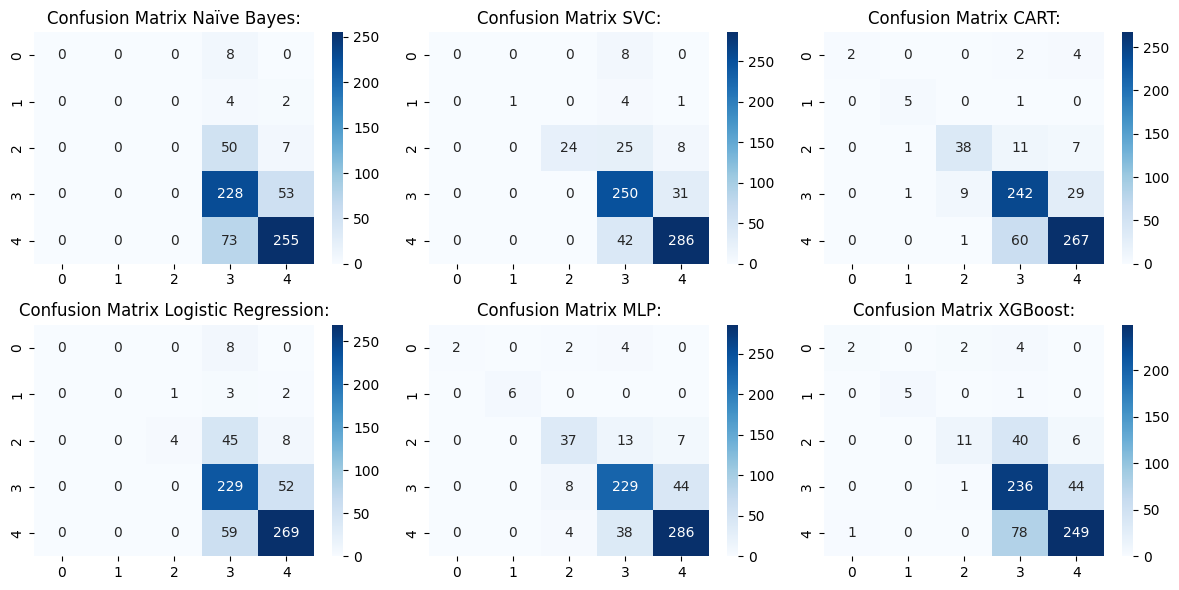

In [42]:
list = [nb_pred, svc_pred,cart_pred,logistic_pred,mlp_pred,xgb_pred]
list_name =["Confusion Matrix Naïve Bayes:" ,"Confusion Matrix SVC:" ,"Confusion Matrix CART:",
             "Confusion Matrix Logistic Regression:","Confusion Matrix MLP:","Confusion Matrix XGBoost:"]
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 6))
j = 0
for i, name in zip(list, list_name):
    subplot = ax[j // 3, j % 3]
    subplot.set_title(name)
    cm = confusion_matrix(y_test, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=subplot)
    j += 1

plt.tight_layout()
plt.show()



## N-gram : 
* n = 1
* 1 <n < 2
* n = 2 

In [43]:
# ngram = 1
X_train, X_test, y_train, y_test = train_test_split(tfidfNgram_df, target, test_size=0.2, random_state=42)

tf_nb_classifier = MultinomialNB()
tf_nb_classifier.fit(X_train, y_train)

tf_svc_classifier = SVC()
tf_svc_classifier.fit(X_train, y_train)

tf_cart_classifier = DecisionTreeClassifier()
tf_cart_classifier.fit(X_train, y_train)

tf_logistic_classifier = LogisticRegression()
tf_logistic_classifier.fit(X_train, y_train)

tf_mlp_classifier = MLPClassifier()
tf_mlp_classifier.fit(X_train, y_train)

tf_xgb_classifier = GradientBoostingClassifier()
tf_xgb_classifier.fit(X_train, y_train)



nb_pred = tf_nb_classifier.predict(X_test)
svc_pred = tf_svc_classifier.predict(X_test)
cart_pred = tf_cart_classifier.predict(X_test)
logistic_pred = tf_logistic_classifier.predict(X_test)
mlp_pred = tf_mlp_classifier.predict(X_test)
xgb_pred = tf_xgb_classifier.predict(X_test)

In [44]:
print("Naïve Bayes:")
print(classification_report(y_test, nb_pred))

print("SVC:")
print(classification_report(y_test, svc_pred))

print("CART:")
print(classification_report(y_test, cart_pred))

print("Logistic Regression:")
print(classification_report(y_test, logistic_pred))

print("MLP:")
print(classification_report(y_test, mlp_pred))

print("XGBoost:")
print(classification_report(y_test, xgb_pred))

Naïve Bayes:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        57
           4       0.63      0.81      0.71       281
           5       0.80      0.78      0.79       328

    accuracy                           0.71       680
   macro avg       0.29      0.32      0.30       680
weighted avg       0.65      0.71      0.67       680

SVC:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       1.00      0.17      0.29         6
           3       1.00      0.42      0.59        57
           4       0.76      0.89      0.82       281
           5       0.88      0.87      0.87       328

    accuracy                           0.82       680
   macro avg       0.73      0.47      0.51       680
weighted avg       0.83      0.82      0.81       680

CART

Naïve Bayes Accuracy: 0.7102941176470589
SVC Accuracy: 0.825
CART Accuracy: 0.8117647058823529
Logistic Regression Accuracy: 0.7382352941176471
MLP Accuracy: 0.8279411764705882
XGBoost Accuracy: 0.7382352941176471


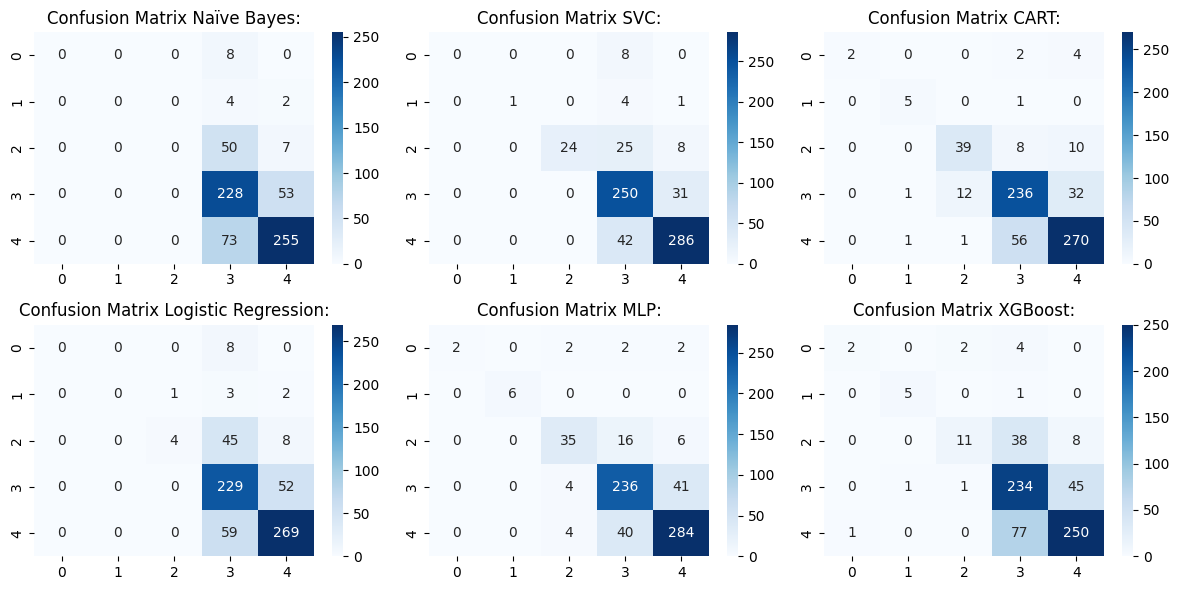

In [45]:
print("Naïve Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print("SVC Accuracy:", accuracy_score(y_test, svc_pred))
print("CART Accuracy:", accuracy_score(y_test, cart_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_pred))
print("MLP Accuracy:", accuracy_score(y_test, mlp_pred))
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
list = [nb_pred, svc_pred,cart_pred,logistic_pred,mlp_pred,xgb_pred]
list_name =["Confusion Matrix Naïve Bayes:" ,"Confusion Matrix SVC:" ,"Confusion Matrix CART:",
             "Confusion Matrix Logistic Regression:","Confusion Matrix MLP:","Confusion Matrix XGBoost:"]
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 6))
j = 0
for i, name in zip(list, list_name):
    subplot = ax[j // 3, j % 3]
    subplot.set_title(name)
    cm = confusion_matrix(y_test, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=subplot)
    j += 1

plt.tight_layout()
plt.show()


In [46]:
#ngram 1 to 2
X_train, X_test, y_train, y_test = train_test_split(tfidfNgram1to2_df, target, test_size=0.2, random_state=42)

tf_nb_classifier = MultinomialNB()
tf_nb_classifier.fit(X_train, y_train)

tf_svc_classifier = SVC()
tf_svc_classifier.fit(X_train, y_train)

tf_cart_classifier = DecisionTreeClassifier()
tf_cart_classifier.fit(X_train, y_train)

tf_logistic_classifier = LogisticRegression()
tf_logistic_classifier.fit(X_train, y_train)

tf_mlp_classifier = MLPClassifier()
tf_mlp_classifier.fit(X_train, y_train)

tf_xgb_classifier = GradientBoostingClassifier()
tf_xgb_classifier.fit(X_train, y_train)



nb_pred = tf_nb_classifier.predict(X_test)
svc_pred = tf_svc_classifier.predict(X_test)
cart_pred = tf_cart_classifier.predict(X_test)
logistic_pred = tf_logistic_classifier.predict(X_test)
mlp_pred = tf_mlp_classifier.predict(X_test)
xgb_pred = tf_xgb_classifier.predict(X_test)

In [47]:
print("Naïve Bayes:")
print(classification_report(y_test, nb_pred))

print("SVC:")
print(classification_report(y_test, svc_pred))

print("CART:")
print(classification_report(y_test, cart_pred))

print("Logistic Regression:")
print(classification_report(y_test, logistic_pred))

print("MLP:")
print(classification_report(y_test, mlp_pred))

print("XGBoost:")
print(classification_report(y_test, xgb_pred))

Naïve Bayes:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        57
           4       0.67      0.85      0.75       281
           5       0.85      0.84      0.84       328

    accuracy                           0.75       680
   macro avg       0.30      0.34      0.32       680
weighted avg       0.69      0.75      0.72       680

SVC:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       0.00      0.00      0.00         6
           3       1.00      0.54      0.70        57
           4       0.77      0.92      0.84       281
           5       0.91      0.87      0.89       328

    accuracy                           0.84       680
   macro avg       0.54      0.47      0.49       680
weighted avg       0.84      0.84      0.83       680

CART

Naïve Bayes Accuracy: 0.7544117647058823
SVC Accuracy: 0.8441176470588235
CART Accuracy: 0.8058823529411765
Logistic Regression Accuracy: 0.7911764705882353
MLP Accuracy: 0.8338235294117647
XGBoost Accuracy: 0.7470588235294118


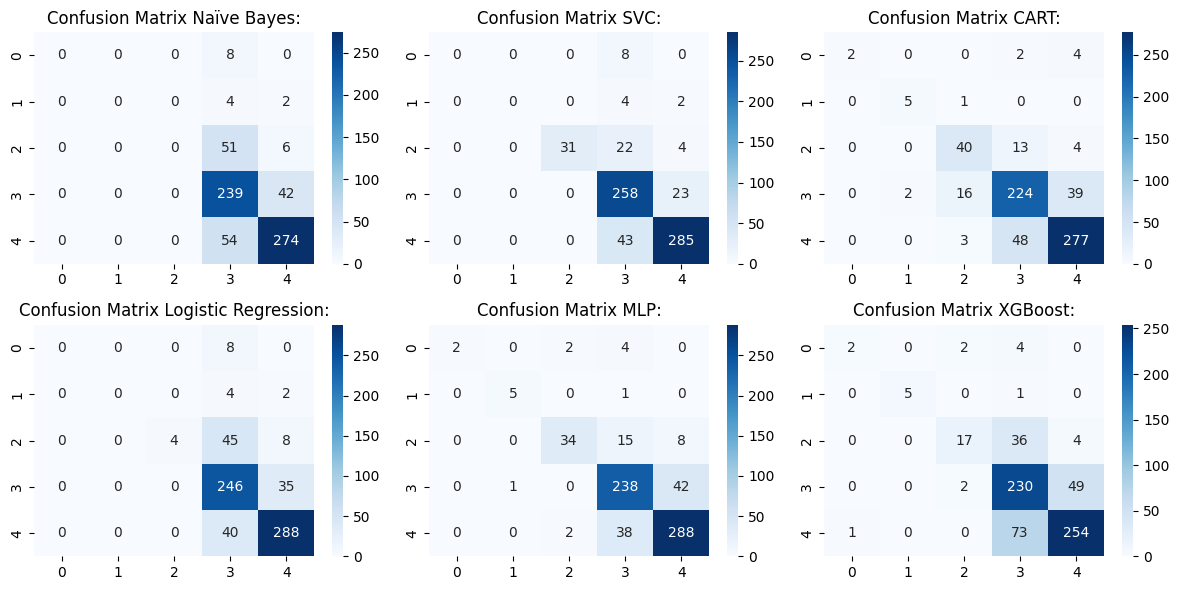

In [48]:
print("Naïve Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print("SVC Accuracy:", accuracy_score(y_test, svc_pred))
print("CART Accuracy:", accuracy_score(y_test, cart_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_pred))
print("MLP Accuracy:", accuracy_score(y_test, mlp_pred))
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
list = [nb_pred, svc_pred,cart_pred,logistic_pred,mlp_pred,xgb_pred]
list_name =["Confusion Matrix Naïve Bayes:" ,"Confusion Matrix SVC:" ,"Confusion Matrix CART:",
             "Confusion Matrix Logistic Regression:","Confusion Matrix MLP:","Confusion Matrix XGBoost:"]
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 6))
j = 0
for i, name in zip(list, list_name):
    subplot = ax[j // 3, j % 3]
    subplot.set_title(name)
    cm = confusion_matrix(y_test, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=subplot)
    j += 1

plt.tight_layout()
plt.show()


In [49]:
# ngram = 2 
X_train, X_test, y_train, y_test = train_test_split(tfidfNgram3_df, target, test_size=0.2, random_state=42)

tf_nb_classifier = MultinomialNB()
tf_nb_classifier.fit(X_train, y_train)

tf_svc_classifier = SVC()
tf_svc_classifier.fit(X_train, y_train)

tf_cart_classifier = DecisionTreeClassifier()
tf_cart_classifier.fit(X_train, y_train)

tf_logistic_classifier = LogisticRegression()
tf_logistic_classifier.fit(X_train, y_train)

tf_mlp_classifier = MLPClassifier()
tf_mlp_classifier.fit(X_train, y_train)

tf_xgb_classifier = GradientBoostingClassifier()
tf_xgb_classifier.fit(X_train, y_train)



nb_pred = tf_nb_classifier.predict(X_test)
svc_pred = tf_svc_classifier.predict(X_test)
cart_pred = tf_cart_classifier.predict(X_test)
logistic_pred = tf_logistic_classifier.predict(X_test)
mlp_pred = tf_mlp_classifier.predict(X_test)
xgb_pred = tf_xgb_classifier.predict(X_test)

In [50]:
print("Naïve Bayes:")
print(classification_report(y_test, nb_pred))

print("SVC:")
print(classification_report(y_test, svc_pred))

print("CART:")
print(classification_report(y_test, cart_pred))

print("Logistic Regression:")
print(classification_report(y_test, logistic_pred))

print("MLP:")
print(classification_report(y_test, mlp_pred))

print("XGBoost:")
print(classification_report(y_test, xgb_pred))

Naïve Bayes:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       0.00      0.00      0.00         6
           3       0.00      0.00      0.00        57
           4       0.72      0.82      0.77       281
           5       0.81      0.89      0.84       328

    accuracy                           0.77       680
   macro avg       0.31      0.34      0.32       680
weighted avg       0.69      0.77      0.73       680

SVC:
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         8
           2       0.00      0.00      0.00         6
           3       1.00      0.58      0.73        57
           4       0.74      0.91      0.82       281
           5       0.91      0.83      0.87       328

    accuracy                           0.83       680
   macro avg       0.53      0.47      0.48       680
weighted avg       0.83      0.83      0.82       680

CART

Naïve Bayes Accuracy: 0.7676470588235295
SVC Accuracy: 0.8279411764705882
CART Accuracy: 0.8058823529411765
Logistic Regression Accuracy: 0.7691176470588236
MLP Accuracy: 0.8176470588235294
XGBoost Accuracy: 0.7205882352941176


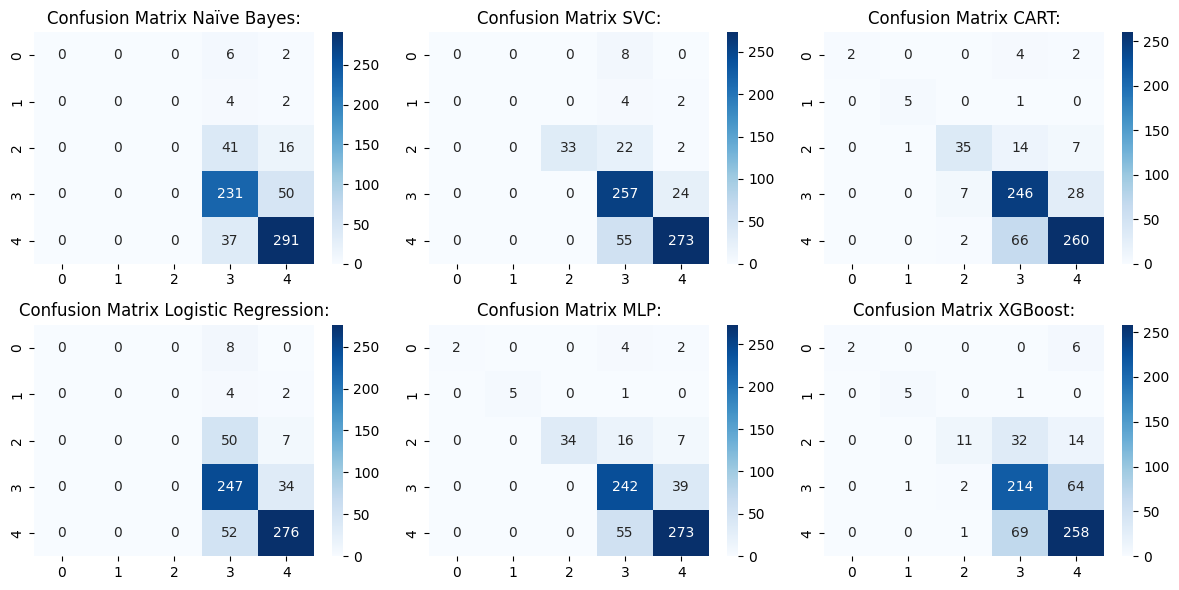

In [51]:
print("Naïve Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print("SVC Accuracy:", accuracy_score(y_test, svc_pred))
print("CART Accuracy:", accuracy_score(y_test, cart_pred))
print("Logistic Regression Accuracy:", accuracy_score(y_test, logistic_pred))
print("MLP Accuracy:", accuracy_score(y_test, mlp_pred))
print("XGBoost Accuracy:", accuracy_score(y_test, xgb_pred))
list = [nb_pred, svc_pred,cart_pred,logistic_pred,mlp_pred,xgb_pred]
list_name =["Confusion Matrix Naïve Bayes:" ,"Confusion Matrix SVC:" ,"Confusion Matrix CART:",
             "Confusion Matrix Logistic Regression:","Confusion Matrix MLP:","Confusion Matrix XGBoost:"]
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(12, 6))
j = 0
for i, name in zip(list, list_name):
    subplot = ax[j // 3, j % 3]
    subplot.set_title(name)
    cm = confusion_matrix(y_test, i)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=subplot)
    j += 1

plt.tight_layout()
plt.show()
